# 05 — Fundamentos de Probabilidade

Na Parte I **descrevemos** dados que já tínhamos. A partir de agora, vamos estudar a **incerteza**: o que pode acontecer e com que chance. Essa é a linguagem da **probabilidade**.

Ela está em todo lugar no ML:
- No ML-02, os classificadores devolviam **probabilidades** (`predict_proba`), e escolhemos **limiares** sobre elas.
- As médias das amostras do notebook 01 variavam por **acaso**, e a probabilidade é o que permite medir esse acaso.
- Separar treino e teste, embaralhar as dobras da validação cruzada e criar uma random forest são processos **aleatórios**.

Neste notebook vamos:
- Definir **experimento, espaço amostral e evento**
- Estimar probabilidades por **simulação** (a visão frequentista)
- Conhecer os **axiomas** e as regras do **complemento** e da **união**
- **Contar** possibilidades com permutações e combinações
- Resolver dois problemas famosos: o **problema do aniversário** e o **problema de Monty Hall**

## 1. Importando bibliotecas

In [1]:
import math        # funções matemáticas do Python puro (fatorial, combinações...)
import itertools   # ferramentas para gerar combinações e permutações

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

## 🎓 Conceito: experimento, espaço amostral e evento

- **Experimento aleatório:** um processo cujo resultado não sabemos de antemão. Exemplo: jogar um dado.
- **Espaço amostral** ($\Omega$, "ômega"): o conjunto de **todos** os resultados possíveis. Para um dado: $\Omega = \{1, 2, 3, 4, 5, 6\}$.
- **Evento:** um subconjunto do espaço amostral, ou seja, uma "pergunta" sobre o resultado. Exemplo: $A$ = "sair número par" = $\{2, 4, 6\}$.

Quando todos os resultados são **igualmente prováveis** (um dado honesto), a probabilidade de um evento é a **definição clássica**:

$$P(A) = \frac{\text{número de resultados favoráveis}}{\text{número de resultados possíveis}} = \frac{3}{6} = 0{,}5$$

In [2]:
# Em Python, conjuntos (set) são escritos com chaves e não têm elementos repetidos.
espaco = {1, 2, 3, 4, 5, 6}
par = {x for x in espaco if x % 2 == 0}   # "set comprehension"; % é o resto da divisão
maior_que_4 = {x for x in espaco if x > 4}

print("Ω =", espaco)
print("A (par) =", par, "  P(A) =", len(par) / len(espaco))
print("B (> 4) =", maior_que_4, "  P(B) =", round(len(maior_que_4) / len(espaco), 4))

# Operações com eventos: interseção (&, "A e B"), união (|, "A ou B") e complemento (Ω - A, "não A").
print("A e B   =", par & maior_que_4)
print("A ou B  =", par | maior_que_4)
print("não A   =", espaco - par)

Ω = {1, 2, 3, 4, 5, 6}
A (par) = {2, 4, 6}   P(A) = 0.5
B (> 4) = {5, 6}   P(B) = 0.3333
A e B   = {6}
A ou B  = {2, 4, 5, 6}
não A   = {1, 3, 5}


## 🎓 Conceito: probabilidade como frequência de longo prazo

Nem sempre os resultados são igualmente prováveis (uma moeda viciada, a chance de chover amanhã). A **visão frequentista** define a probabilidade como a **proporção de vezes** em que o evento acontece quando o experimento é repetido **muitíssimas vezes**.

Com o computador, podemos repetir um experimento milhões de vezes em segundos. Isso nos dá uma ferramenta poderosíssima: **estimar probabilidades por simulação**, mesmo quando não sabemos (ou não queremos) fazer a conta. É o chamado **método de Monte Carlo** (notebook extra 18).

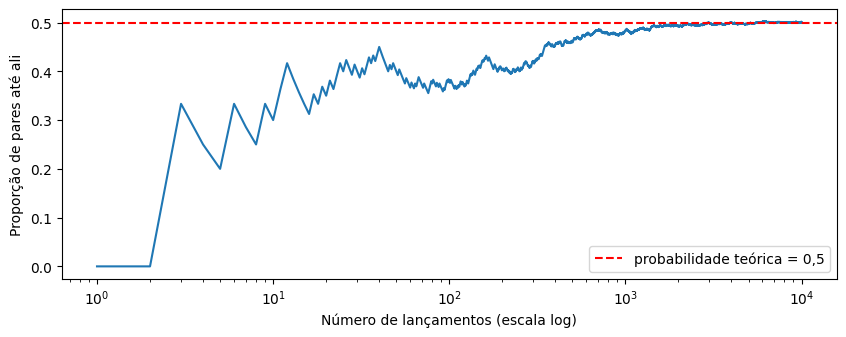

Depois de     10 lançamentos: proporção de pares = 0.3000
Depois de    100 lançamentos: proporção de pares = 0.3800
Depois de   1000 lançamentos: proporção de pares = 0.4840
Depois de  10000 lançamentos: proporção de pares = 0.5014


In [3]:
# 10.000 lançamentos de um dado: integers sorteia inteiros de 1 até 6 (o 7 é exclusivo).
lancamentos = rng.integers(1, 7, size=10_000)
eh_par = (lancamentos % 2 == 0)

# np.cumsum é a soma acumulada; dividindo pelo número de lançamentos até ali, temos a proporção "até agora".
proporcao_acumulada = np.cumsum(eh_par) / np.arange(1, len(lancamentos) + 1)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(1, len(lancamentos) + 1), proporcao_acumulada)
ax.axhline(0.5, color="red", linestyle="--", label="probabilidade teórica = 0,5")
ax.set_xscale("log")   # eixo x em escala logarítmica: 1, 10, 100, 1000... ficam igualmente espaçados
ax.set_xlabel("Número de lançamentos (escala log)")
ax.set_ylabel("Proporção de pares até ali")
ax.legend()
plt.show()

for n in [10, 100, 1_000, 10_000]:
    print(f"Depois de {n:>6} lançamentos: proporção de pares = {proporcao_acumulada[n - 1]:.4f}")   # :>6 alinha à direita

**Conclusão:** com poucos lançamentos, a proporção de pares oscila bastante: **0,30** depois de 10 lançamentos e 0,38 depois de 100, longe de 0,5. Com mais repetições, ela se aproxima da probabilidade teórica: **0,484** com 1.000 e **0,5014** com 10.000. No gráfico, a curva começa "nervosa" à esquerda e vai se acalmando em torno da linha vermelha.

Esse comportamento tem nome, **Lei dos Grandes Números**, e será o assunto do notebook 10. Repare também que, mesmo com 10.000 lançamentos, a proporção não é **exatamente** 0,5: a simulação é uma **estimativa**, com uma pequena incerteza.

## 🎓 Conceito: axiomas e regras básicas

Toda probabilidade, de qualquer tipo, obedece a três regras (os **axiomas de Kolmogorov**):
1. $0 \le P(A) \le 1$ para qualquer evento.
2. $P(\Omega) = 1$: **algum** resultado sempre acontece.
3. Se $A$ e $B$ **não podem acontecer juntos** (são *disjuntos*), $P(A \text{ ou } B) = P(A) + P(B)$.

Delas saem as regras que usaremos o tempo todo:
- **Complemento:** $P(\text{não } A) = 1 - P(A)$. Muitas vezes é mais fácil calcular a chance de algo **não** acontecer.
- **União (regra da soma geral):** $P(A \text{ ou } B) = P(A) + P(B) - P(A \text{ e } B)$. Subtraímos a interseção porque ela foi contada **duas vezes**.

Vamos conferir com dois dados: $A$ = "a soma é 7" e $B$ = "pelo menos um dado é 6".

In [4]:
# Todas as 36 combinações de dois dados, com itertools.product (o "produto cartesiano").
todos = list(itertools.product(range(1, 7), repeat=2))
print(f"{len(todos)} resultados possíveis, por exemplo: {todos[:4]}")

# Probabilidade clássica: contar os favoráveis. sum(...) com uma condição conta os True.
p_A = sum(d1 + d2 == 7 for d1, d2 in todos) / 36
p_B = sum(d1 == 6 or d2 == 6 for d1, d2 in todos) / 36
p_A_e_B = sum(d1 + d2 == 7 and (d1 == 6 or d2 == 6) for d1, d2 in todos) / 36
p_A_ou_B = sum(d1 + d2 == 7 or d1 == 6 or d2 == 6 for d1, d2 in todos) / 36

print(f"P(A) = {p_A:.4f}   P(B) = {p_B:.4f}   P(A e B) = {p_A_e_B:.4f}")
print(f"P(A ou B) contando:          {p_A_ou_B:.4f}")
print(f"P(A) + P(B) - P(A e B):      {p_A + p_B - p_A_e_B:.4f}")
print(f"P(A) + P(B) (errado!):       {p_A + p_B:.4f}")

# A mesma coisa por simulação: 1 milhão de pares de dados.
d1 = rng.integers(1, 7, size=1_000_000)
d2 = rng.integers(1, 7, size=1_000_000)
A = (d1 + d2 == 7)
B = (d1 == 6) | (d2 == 6)
print(f"\nSimulação: P(A ou B) ≈ {np.mean(A | B):.4f}   P(não B) ≈ {np.mean(~B):.4f} (teoria: {1 - p_B:.4f})")   # ~ é o "não"

36 resultados possíveis, por exemplo: [(1, 1), (1, 2), (1, 3), (1, 4)]
P(A) = 0.1667   P(B) = 0.3056   P(A e B) = 0.0556
P(A ou B) contando:          0.4167
P(A) + P(B) - P(A e B):      0.4167
P(A) + P(B) (errado!):       0.4722

Simulação: P(A ou B) ≈ 0.4163   P(não B) ≈ 0.6949 (teoria: 0.6944)


**Conclusão:** somar $P(A) + P(B)$ dá **0,4722**, mas a resposta certa é **0,4167** (15 dos 36 resultados). A diferença, **0,0556** (2/36), é a interseção: os resultados (1, 6) e (6, 1) têm soma 7 **e** um 6, e foram contados duas vezes. A regra da união corrige exatamente isso.

Com 1 milhão de simulações, chegamos a **0,4163** para a união e **0,6949** para o complemento "nenhum dado é 6", contra 0,6944 da teoria ($25/36$). A simulação acerta até a terceira casa decimal.

## 🎓 Conceito: contagem (permutações e combinações)

Para usar a definição clássica, precisamos **contar** resultados, e às vezes eles são muitos. Três ferramentas resolvem quase tudo:

- **Princípio multiplicativo:** se uma escolha tem $a$ opções e outra tem $b$, as duas juntas têm $a \times b$. (Dois dados: 6 × 6 = 36.)
- **Permutações (a ordem importa):** de quantas formas podemos ordenar $n$ objetos? $n! = n \times (n-1) \times \dots \times 1$ (lê-se "n fatorial"). Escolher e ordenar $k$ de $n$: $\frac{n!}{(n-k)!}$.
- **Combinações (a ordem não importa):** de quantas formas podemos escolher $k$ de $n$ objetos?
$$\binom{n}{k} = \frac{n!}{k!\,(n-k)!}$$
  Lê-se "n escolhe k". É o que importa numa loteria: o sorteio 1-2-3 é o mesmo que 3-2-1.

In [5]:
# Pódio de uma corrida com 8 atletas: ordem importa (ouro, prata e bronze são diferentes).
print(f"Pódios possíveis com 8 atletas: {math.perm(8, 3)}")

# Comissão de 3 pessoas escolhidas entre 8: ordem não importa.
print(f"Comissões de 3 entre 8:         {math.comb(8, 3)}   (= {math.perm(8, 3)} / 3! = {math.perm(8, 3)} / {math.factorial(3)})")

# Conferindo com itertools: gerar todas as combinações e contá-las.
print(f"Contando com itertools:         {len(list(itertools.combinations(range(8), 3)))}")

# Mega-Sena: escolher 6 números entre 60.
total_megasena = math.comb(60, 6)
print(f"\nMega-Sena: {total_megasena:,} combinações → P(ganhar com 1 aposta) = 1 em {total_megasena:,}".replace(",", "."))

Pódios possíveis com 8 atletas: 336
Comissões de 3 entre 8:         56   (= 336 / 3! = 336 / 6)
Contando com itertools:         56

Mega-Sena: 50.063.860 combinações → P(ganhar com 1 aposta) = 1 em 50.063.860


**Conclusão:** com 8 atletas há **336** pódios possíveis, mas só **56** comissões de 3 pessoas: cada comissão corresponde a $3! = 6$ pódios diferentes (as 6 ordens das mesmas 3 pessoas), e 336 / 6 = 56. O `itertools` confirma, gerando e contando as 56 combinações.

Na Mega-Sena há **50.063.860** combinações de 6 números. Uma aposta simples tem 1 chance em 50 milhões, menos que a chance de acertar o lado de uma moeda **25 vezes seguidas** ($2^{25} \approx 33{,}5$ milhões).

## 2. O problema do aniversário

Numa sala com $n$ pessoas, qual a chance de **pelo menos duas** fazerem aniversário no mesmo dia? (Vamos ignorar anos bissextos e supor que todos os dias são igualmente prováveis.)

A intuição costuma errar feio aqui. A conta fica fácil com o **complemento**: calculamos a chance de **todos** fazerem aniversário em dias **diferentes**:

$$P(\text{todos diferentes}) = \frac{365}{365} \times \frac{364}{365} \times \frac{363}{365} \times \dots \times \frac{365 - n + 1}{365}$$

A primeira pessoa pode nascer em qualquer dia; a segunda tem 364 dias "livres"; a terceira, 363; e assim por diante. Depois, $P(\text{alguma coincidência}) = 1 - P(\text{todos diferentes})$.

In [6]:
def prob_aniversario(n):
    """Probabilidade exata de pelo menos uma coincidência de aniversário entre n pessoas."""
    # np.prod multiplica todos os elementos; np.arange(365, 365 - n, -1) = 365, 364, ..., 365 - n + 1
    return 1 - np.prod(np.arange(365, 365 - n, -1) / 365)


def simular_aniversario(n, repeticoes=20_000):
    """Estimativa por simulação: sorteia aniversários e verifica se há algum repetido."""
    salas = rng.integers(0, 365, size=(repeticoes, n))   # cada linha é uma sala
    salas.sort(axis=1)                                  # ordena cada sala: dias repetidos ficam vizinhos
    tem_repetido = (np.diff(salas, axis=1) == 0).any(axis=1)   # diff = diferença entre vizinhos; 0 = repetido
    return tem_repetido.mean()


tamanhos = [5, 10, 20, 23, 30, 40, 50, 70]
pd.DataFrame({
    "exata": [prob_aniversario(n) for n in tamanhos],
    "simulação": [simular_aniversario(n) for n in tamanhos],
}, index=pd.Index(tamanhos, name="pessoas na sala"))

,exata,simulação
pessoas na sala,,
5,0.0271,0.0257
10,0.1169,0.1190
20,0.4114,0.4124
23,0.5073,0.5042
30,0.7063,0.7142
40,0.8912,0.8917
50,0.9704,0.9698
70,0.9992,0.9992


**Conclusão:** com apenas **23 pessoas**, a chance de haver um aniversário repetido já passa de 50% (**50,7%**); com 50 pessoas, chega a **97%**; com 70, a **99,9%**. A simulação concorda com a fórmula em todos os tamanhos (diferenças de no máximo ~1 ponto percentual, que é a incerteza de 20.000 repetições).

Por que a intuição erra? Ela pensa em "alguém fazer aniversário no **meu** dia", mas o que conta são **todos os pares** de pessoas: com 23 pessoas há $\binom{23}{2} = 253$ pares, e cada um é uma chance de coincidência.

🔗 **Ponte para o ML:** o mesmo raciocínio explica por que, testando muitas hipóteses ou muitos modelos, **alguma** coincidência impressionante quase sempre aparece por acaso (a "maldição do vencedor" do ML-01 e os testes múltiplos do notebook 12).

## 3. O problema de Monty Hall

Num programa de TV, há **três portas**: atrás de uma está um carro; atrás das outras duas, cabras. Você escolhe uma porta. O apresentador, que **sabe** onde está o carro, abre uma das outras portas e mostra uma cabra. Então ele pergunta: **você quer trocar de porta?**

A maioria das pessoas (inclusive muitos matemáticos, quando o problema ficou famoso) responde: "tanto faz, sobraram duas portas, é 50% para cada". Vamos **simular**.

In [7]:
def monty_hall(trocar, repeticoes=100_000):
    """Simula o jogo e devolve a proporção de vitórias com a estratégia escolhida."""
    carro = rng.integers(0, 3, size=repeticoes)     # porta do carro em cada jogo
    escolha = rng.integers(0, 3, size=repeticoes)   # primeira escolha do jogador
    # O apresentador abre uma porta que não é a escolhida nem a do carro. Se o jogador TROCA,
    # ele fica com a única porta que sobra. Logo: trocando, ganha exatamente quando a primeira escolha estava ERRADA.
    if trocar:
        return np.mean(escolha != carro)
    return np.mean(escolha == carro)


print(f"Ficando com a porta:  ganha {monty_hall(trocar=False):.1%} das vezes")
print(f"Trocando de porta:    ganha {monty_hall(trocar=True):.1%} das vezes")

Ficando com a porta:  ganha 33.3% das vezes
Trocando de porta:    ganha 66.7% das vezes


**Conclusão:** trocar de porta ganha **66,7%** das vezes, o **dobro** de ficar (**33,3%**). O raciocínio da simulação explica: a primeira escolha acerta o carro em 1/3 das vezes. Nesses casos, trocar faz perder. Nos outros **2/3**, o jogador escolheu uma cabra; o apresentador é **obrigado** a abrir a outra cabra, e a porta que sobra **é o carro**. Trocar ganha exatamente quando a primeira escolha estava errada.

O ponto crucial é que o apresentador **não abre uma porta ao acaso**: ele usa o que sabe. A porta aberta traz **informação**, e informação muda as probabilidades.

## 🎓 Conceito: três interpretações da probabilidade

| Interpretação | O que é $P(A)$ | Exemplo |
|---|---|---|
| **Clássica** | favoráveis / possíveis, com resultados igualmente prováveis | dados, cartas, loterias |
| **Frequentista** | proporção de vezes em infinitas repetições | taxa de defeitos de uma fábrica |
| **Bayesiana (subjetiva)** | grau de **crença**, atualizado com evidências | "70% de chance de o time ganhar o jogo de domingo" |

A frequentista não serve bem para eventos que **não se repetem** (o jogo de domingo só acontece uma vez). A bayesiana trata a probabilidade como uma medida de incerteza que se **atualiza** quando chegam dados novos. Vamos explorá-la nos notebooks 06 (Teorema de Bayes) e 16 (inferência bayesiana).

As três obedecem aos **mesmos axiomas**, então todas as regras deste notebook valem para qualquer uma delas.

🔗 **Ponte para o ML:** quando um classificador do ML-02 diz "73% de chance de renda alta" para uma pessoa específica, a interpretação mais natural é a frequentista "entre muitas pessoas parecidas com essa, 73% têm renda alta". É exatamente o que a **calibração** (notebook 06 do ML-02) verifica.

## 4. Resumo e próximos passos

**Conceitos que você aprendeu**
- **Experimento, espaço amostral e evento**; operações com eventos (e, ou, não).
- Probabilidade **clássica** e **frequentista**, e a estimativa por **simulação**.
- **Axiomas**, regra do **complemento** e regra da **união**.
- **Contagem:** princípio multiplicativo, permutações e combinações.
- O **problema do aniversário** (a intuição subestima coincidências) e o problema de **Monty Hall** (a informação do apresentador muda as chances).

**Python novo:** `math.comb` / `perm` / `factorial`, `itertools.product` / `combinations`, conjuntos (`set`) com `&`, `|` e `-`, `%`, `rng.integers`, `np.cumsum`, `np.prod`, `np.diff`, `~` para negar máscaras, `ax.set_xscale("log")`, formatação `:>6`.

**Próximo notebook:** no Monty Hall, a porta que o apresentador abriu **mudou as chances**. Isso é a **probabilidade condicional**: a probabilidade de algo **dado** que sabemos outra coisa. No notebook 06 vamos formalizá-la e chegar ao **Teorema de Bayes**, base do classificador Naive Bayes e da forma como interpretamos exames médicos e alarmes.